In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import pyarrow
from pathlib import Path

In [2]:
BASE_DIR = Path.cwd().resolve().parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

In [3]:
df_cap200a = pd.read_parquet(RAW_DIR / "03_CAP200A.parquet")
df_caratula = pd.read_parquet(RAW_DIR / "CARATULA.parquet")

In [4]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
peru = gpd.read_file(ruta_mapa)

In [5]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_provinvial = BASE_DIR / "data"/"processed"/"LIM_PROVINCIAL_PERU.json"
peru = gpd.read_file(ruta_mapa)
provincias_peru = gpd.read_file(ruta_provinvial)

# 1. Análisis de la región de Piura

In [6]:
provincias = provincias_peru.copy()
provinvias_piu = provincias_peru[
    provincias_peru["NOMBDEP"].str.upper().eq("PIURA")
]
provinvias_piu.head(8)

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry
58,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825..."
59,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965..."
60,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106..."
61,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279..."
62,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594..."
63,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795..."
64,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433..."
65,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177..."


In [7]:
df_piura = df_cap200a[df_cap200a["NOMBREDD"]=="PIURA"].copy()

In [8]:
print(df_piura["NOMBREPV"].unique())
print(provinvias_piu["NOMBPROV"].unique())

<ArrowStringArray>
['SECHURA', 'PAITA', 'MORROPON', 'HUANCABAMBA', 'AYABACA', 'PIURA']
Length: 6, dtype: str
<ArrowStringArray>
[    'AYABACA', 'HUANCABAMBA',    'MORROPON',       'PAITA',       'PIURA',
     'SECHURA',     'SULLANA',      'TALARA']
Length: 8, dtype: str


In [9]:
df_cap200a.loc[df_cap200a["NOMBREDD"] == "PIURA", "NOMBREPV"].unique()

<ArrowStringArray>
['SECHURA', 'PAITA', 'MORROPON', 'HUANCABAMBA', 'AYABACA', 'PIURA']
Length: 6, dtype: str

In [10]:
df_caratula.loc[df_caratula["NOMBREDD"] == "PIURA", "NOMBREPV"].unique()

<ArrowStringArray>
[    'SECHURA',      'TALARA',     'SULLANA',       'PAITA',    'MORROPON',
 'HUANCABAMBA',     'AYABACA',       'PIURA']
Length: 8, dtype: str

## 1.1.2. Producción promedio de pastos por provincia

In [11]:
df_piura[[
    "P218C_PROD_CORTE_ENT",
    "P218C_PROD_CORTE_DEC"
]].head(10)

,P218C_PROD_CORTE_ENT,P218C_PROD_CORTE_DEC
13739,80,0
13740,80,0
13741,80,0
13742,80,0
13743,80,0
13744,80,0
13745,0,750
13746,0,750
13747,0,750
13748,0,750


In [12]:
df_piura["produccion_pastos"] = (
    df_piura["P218C_PROD_CORTE_ENT"] +
    df_piura["P218C_PROD_CORTE_DEC"] / 1000
)

df_piura.loc[:, ["produccion_pastos", "P218C_PROD_CORTE_ENT", "P218C_PROD_CORTE_DEC"]].head(10)

,produccion_pastos,P218C_PROD_CORTE_ENT,P218C_PROD_CORTE_DEC
13739,80.00,80,0
13740,80.00,80,0
13741,80.00,80,0
13742,80.00,80,0
13743,80.00,80,0
13744,80.00,80,0
13745,0.75,0,750
13746,0.75,0,750
13747,0.75,0,750
13748,0.75,0,750


In [13]:
resumen_piura_produc = df_piura.groupby("NOMBREPV")["produccion_pastos"].agg(
    total = "sum",
    promedio = "mean",
    n = "size",
    mediana = "median"
).reset_index().round(2)

resumen_piura_produc.head(5)

,NOMBREPV,total,promedio,n,mediana
0,AYABACA,18930.75,119.06,159,15.0
1,HUANCABAMBA,113237.75,654.55,173,8.0
2,MORROPON,135528.50,630.37,215,10.0
3,PAITA,26213.25,708.47,37,125.0
4,PIURA,1550.00,17.42,89,8.0


In [14]:
piura_prod_merge = provinvias_piu.merge(
    resumen_piura_produc,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()

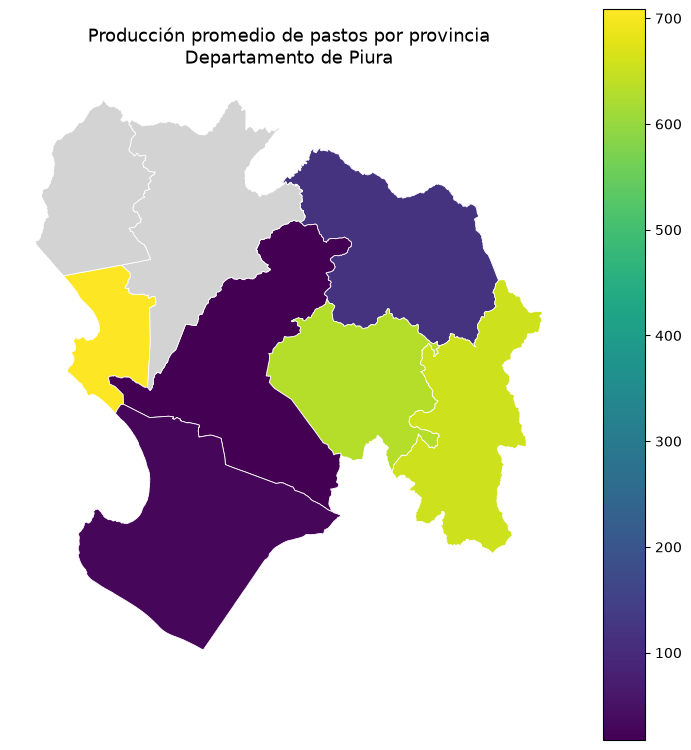

In [15]:
fig, ax = plt.subplots(figsize=(9, 11))

piura_prod_merge.plot(
    column="promedio",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    }
)

ax.set_title(
    "Producción promedio de pastos por provincia\n"
    "Departamento de Piura",
    fontsize=13
)

ax.set_axis_off()
plt.show()

## 1.1.3. ¿Cuál es la cantidad de producción de pastos registrada por provincia, diferenciando entre corte y pastoreo?

In [16]:
resumen_modalidad_piura = (
    df_piura
    .groupby(["NOMBREPV", "P218A"])["produccion_pastos"]
    .agg(
        total="sum",
        promedio="mean",
        n="count",
        mediana="median"
    )
    .reset_index()
    .round(2)
)

resumen_modalidad_piura

,NOMBREPV,P218A,total,promedio,n,mediana
0,AYABACA,1,408.75,12.02,34,6.00
1,AYABACA,2,18522.00,148.18,125,18.75
2,HUANCABAMBA,1,10922.75,227.56,48,2.47
3,HUANCABAMBA,2,102315.00,818.52,125,16.00
4,MORROPON,1,2301.75,43.43,53,20.17
5,MORROPON,2,133226.75,822.39,162,9.00
6,PAITA,1,26213.25,708.47,37,125.00
7,PIURA,1,1529.50,19.86,77,10.00
8,PIURA,2,20.50,1.71,12,1.75
9,SECHURA,1,487.70,30.48,16,0.80


In [17]:
resumen_tipo_corte_piura = pd.crosstab(
    resumen_modalidad_piura["NOMBREPV"],
    resumen_modalidad_piura["P218A"],
    resumen_modalidad_piura["promedio"],
    aggfunc="mean")
resumen_tipo_corte_piura = resumen_tipo_corte_piura.rename(columns={
    1: "Corte",
    2: "Pastoreo"
})
resumen_tipo_corte_piura

P218A,Corte,Pastoreo
NOMBREPV,,
AYABACA,12.02,148.18
HUANCABAMBA,227.56,818.52
MORROPON,43.43,822.39
PAITA,708.47,NaN
PIURA,19.86,1.71
SECHURA,30.48,NaN


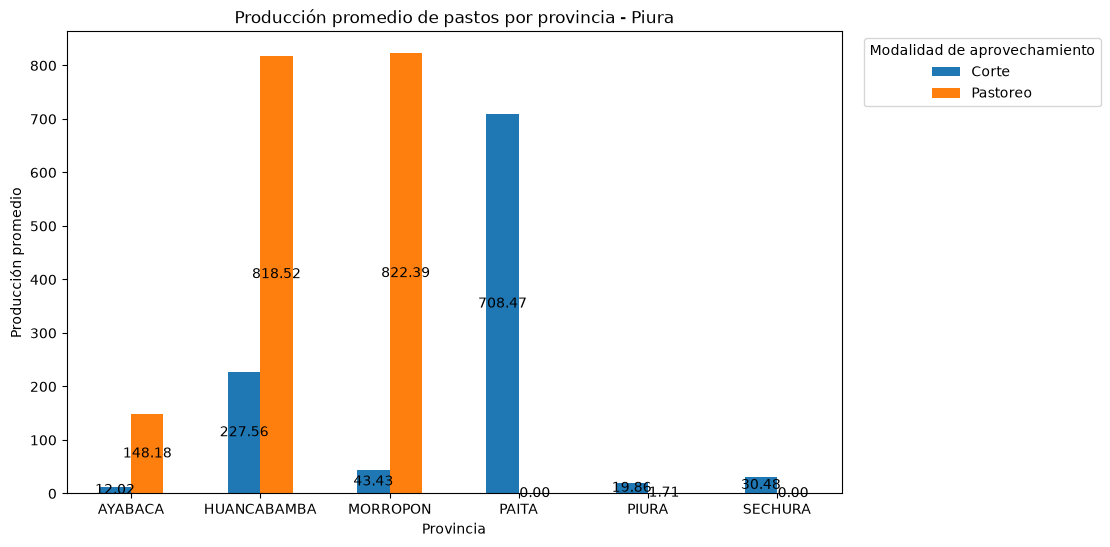

In [18]:
gr_piura_corte = resumen_tipo_corte_piura.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6)
)
gr_piura_corte.set_title("Producción promedio de pastos por provincia - Piura")
gr_piura_corte.set_xlabel("Provincia")
gr_piura_corte.set_ylabel("Producción promedio")  

gr_piura_corte.legend(
    title = "Modalidad de aprovechamiento",
    bbox_to_anchor = (1.02, 1),
    loc = "upper left"
)

for container in gr_piura_corte.containers:
    gr_piura_corte.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 0)
plt.show()

In [19]:
df_piura["P147"].value_counts()

P147
1    431
2    169
3     50
4     25
5      8
6      6
Name: count, dtype: int64

## 1.1.4. Número promedio de terreno registrado por provincia

In [20]:
#P147 registra el número del terreno (o chacra) donde se sembró o cosechó algo, sin importar si el cultivo es distinto o es el mismo.

In [21]:
terrenos_por_productor = (
    df_piura.groupby(["NOMBREPV", "ID_PROD"])["P147"]
    .nunique()  # Cuenta los terrenos reales y diferentes, eliminando duplicados por cultivos
    .reset_index(name="total_terrenos_propios")
)

resumen_terrenos_piura = (
    terrenos_por_productor.groupby("NOMBREPV")["total_terrenos_propios"]
    .agg(
        promedio="mean",
        mediana="median",
        n_productores="count"  # Número real de productores encuestados en la provincia
    )
    .reset_index()
    .round(2)
)

resumen_terrenos_piura

,NOMBREPV,promedio,mediana,n_productores
0,AYABACA,2.25,2.0,12
1,HUANCABAMBA,2.00,1.5,10
2,MORROPON,2.71,3.0,7
3,PAITA,1.67,2.0,3
4,PIURA,1.33,1.0,6
5,SECHURA,1.00,1.0,2


In [22]:
terrenos_por_productor

,NOMBREPV,ID_PROD,total_terrenos_propios
0,AYABACA,1,5
1,AYABACA,2,3
2,AYABACA,3,2
3,AYABACA,4,2
4,AYABACA,5,2
5,AYABACA,6,2
6,AYABACA,7,2
7,AYABACA,8,1
8,AYABACA,9,3
9,AYABACA,10,3


In [47]:
df_piura.loc[df_piura["ID_PROD"] == 5, ["NOMBREPV", "ID_PROD", "P147"]].head(50)

,NOMBREPV,ID_PROD,P147
13860,MORROPON,5,1
13861,MORROPON,5,1
13995,MORROPON,5,1
13996,MORROPON,5,1
13997,MORROPON,5,1
14050,HUANCABAMBA,5,2
14051,HUANCABAMBA,5,2
14055,HUANCABAMBA,5,1
14056,HUANCABAMBA,5,1
14082,HUANCABAMBA,5,1


In [29]:
df_piura.loc[:, ["NOMBREPV","ID_PROD", "P147" ]].head(60)
#el productor 4 tiene 6 parcelas metidas dentro del Terreno 3

,NOMBREPV,ID_PROD,P147
13739,SECHURA,4,3
13740,SECHURA,4,3
13741,SECHURA,4,3
13742,SECHURA,4,3
13743,SECHURA,4,3
13744,SECHURA,4,3
13745,SECHURA,3,2
13746,SECHURA,3,2
13747,SECHURA,3,2
13748,SECHURA,3,2


In [24]:
piura_merge_terreno = provinvias_piu.merge(
    resumen_terrenos_piura,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()
piura_merge_terreno

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREPV,promedio,mediana,n_productores
0,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825...",AYABACA,2.25,2.0,12.0
1,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965...",HUANCABAMBA,2.00,1.5,10.0
2,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106...",MORROPON,2.71,3.0,7.0
3,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279...",PAITA,1.67,2.0,3.0
4,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594...",PIURA,1.33,1.0,6.0
5,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795...",SECHURA,1.00,1.0,2.0
6,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433...",NaN,NaN,NaN,NaN
7,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177...",NaN,NaN,NaN,NaN


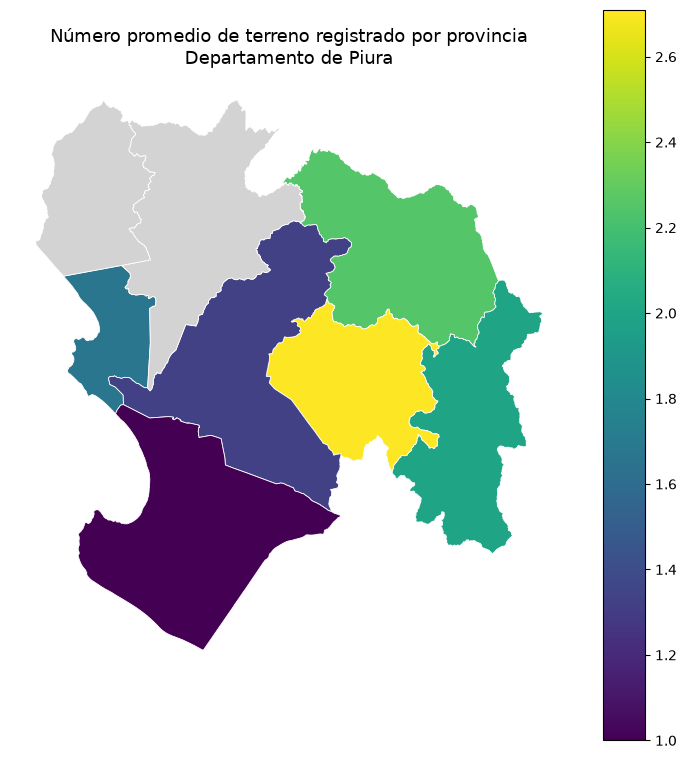

In [25]:
fig, ax = plt.subplots(figsize=(9, 11))

piura_merge_terreno.plot(
    column="promedio",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    }
)

ax.set_title(
    "Número promedio de terreno registrado por provincia\n"
    "Departamento de Piura",
    fontsize=13
)

ax.set_axis_off()
plt.show()